In [2]:
import os
import sys
import random
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

In [29]:
from models.als import ALSCandidateModel

from models.graph_model import (
    train_graph_model,
    extract_graph_embeddings,
)

from src import (
    temporal_train_validation_test_split,
    build_heterogeneous_graph,
    ndcg_at_k_from_scores,
    evaluate_ndcg_at_k
)

In [ ]:
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

### Загрузка и разделение данных

In [5]:
interactions = pd.read_csv(
    PROJECT_ROOT / "data" / "interactions.csv"
)

users = pd.read_csv(
    PROJECT_ROOT / "data" / "users.csv"
)

items = pd.read_csv(
    PROJECT_ROOT / "data" / "items.csv"
)

print("Interactions:", interactions.shape)
print("Users:", users.shape)
print("Items:", items.shape)

Interactions: (1594787, 5)
Users: (840197, 5)
Items: (15963, 14)


In [6]:
TRAIN_CUTOFF = "2021-07-01"
VALIDATION_CUTOFF = "2021-08-01"

train, validation, test = (
    temporal_train_validation_test_split(
        interactions=interactions,
        train_cutoff=TRAIN_CUTOFF,
        validation_cutoff=VALIDATION_CUTOFF,
        date_col="last_watch_dt",
        drop_invalid_dates=True,
    )
)

/var/folders/ds/jdj_sy6s67ncz787qzz3xpc00000gn/T/ipykernel_22403/3133289678.py:5: UserWarning: Dropped 1 rows with missing or invalid 'last_watch_dt'
  temporal_train_validation_test_split(


In [ ]:
SAMPLE_SIZE = 10_000
SAMPLE_RANDOM_STATE = 42

warm_user_ids = (
    train["user_id"]
    .drop_duplicates()
    .to_numpy()
)

rng = np.random.default_rng(
    SAMPLE_RANDOM_STATE
)

sampled_user_ids = np.sort(
    rng.choice(
        warm_user_ids,
        size=min(
            SAMPLE_SIZE,
            len(warm_user_ids),
        ),
        replace=False,
    )
)

In [8]:
train = (
    train[
        train["user_id"].isin(sampled_user_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

validation = (
    validation[
        validation["user_id"].isin(sampled_user_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

test = (
    test[
        test["user_id"].isin(sampled_user_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Train:",
    len(train),
    train["user_id"].nunique(),
)

print(
    "Validation:",
    len(validation),
    validation["user_id"].nunique(),
)

print(
    "Test:",
    len(test),
    test["user_id"].nunique(),
)

Train: 24700 10000
Validation: 5466 2272
Test: 2998 1391


In [9]:
validation_targets = (
    validation[
        ["user_id", "item_id"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

test_targets = (
    test[
        ["user_id", "item_id"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

### ALS кандидатогенерация

In [11]:
K = 200
BATCH_SIZE = 2_000

best_params = {
    "factors": 32,
    "regularization": 0.05,
    "alpha": 10.0,
    "iterations": 20,
}

In [12]:
validation_als = ALSCandidateModel(
    **best_params,
    random_state=RANDOM_STATE,
    num_threads=0,
)

validation_als.fit(
    interactions=train[
        ["user_id", "item_id"]
    ],
    show_progress=True,
)

  0%|          | 0/20 [00:00<?, ?it/s]

In [13]:
validation_user_ids = (
    validation_targets["user_id"]
    .drop_duplicates()
    .tolist()
)

validation_candidates = (
    validation_als.recommend(
        user_ids=validation_user_ids,
        n=K,
        filter_seen=True,
        batch_size=BATCH_SIZE,
    )
)

validation_candidates = (
    validation_candidates
    .sort_values(["user_id", "als_rank"])
    .reset_index(drop=True)
)

print(validation_candidates.shape)
display(validation_candidates.head())

(454400, 4)


,user_id,item_id,als_score,als_rank
0,840,9728,1.180441,1
1,840,8618,0.673944,2
2,840,3509,0.571294,3
3,840,2916,0.565092,4
4,840,14317,0.554531,5


### GraphSAGE + скалярное произведение

In [14]:
train_graph = build_heterogeneous_graph(
    interactions=train,
    users=users,
    items=items,
    cutoff=TRAIN_CUTOFF,
)

In [15]:
print(train_graph.data)

HeteroData(
  user={
    num_nodes=10000,
    x=[10000, 20],
  },
  item={
    num_nodes=3791,
    x=[3791, 7],
  },
  genre={ num_nodes=72 },
  country={ num_nodes=75 },
  content_type={ num_nodes=2 },
  (user, watched, item)={ edge_index=[2, 24700] },
  (item, watched_by, user)={ edge_index=[2, 24700] },
  (item, has_genre, genre)={ edge_index=[2, 9706] },
  (genre, genre_of, item)={ edge_index=[2, 9706] },
  (item, made_in, country)={ edge_index=[2, 4955] },
  (country, country_of, item)={ edge_index=[2, 4955] },
  (item, has_type, content_type)={ edge_index=[2, 3791] },
  (content_type, type_of, item)={ edge_index=[2, 3791] }
)


In [16]:
graph_params = {
    "hidden_dim": 64,
    "num_layers": 2,
    "dropout": 0.1,
    "epochs": 100,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "negatives_per_positive": 5,
    "embedding_regularization": 1e-6,
}

In [17]:
graph_training_result = train_graph_model(
    graph=train_graph,
    **graph_params,
    random_state=RANDOM_STATE,
    verbose=10,
)

Epoch 001/100: BPR loss = 3.618484
Epoch 010/100: BPR loss = 0.430548
Epoch 020/100: BPR loss = 0.335901
Epoch 030/100: BPR loss = 0.296275
Epoch 040/100: BPR loss = 0.258948
Epoch 050/100: BPR loss = 0.239457
Epoch 060/100: BPR loss = 0.222125
Epoch 070/100: BPR loss = 0.206519
Epoch 080/100: BPR loss = 0.193594
Epoch 090/100: BPR loss = 0.175412
Epoch 100/100: BPR loss = 0.161473


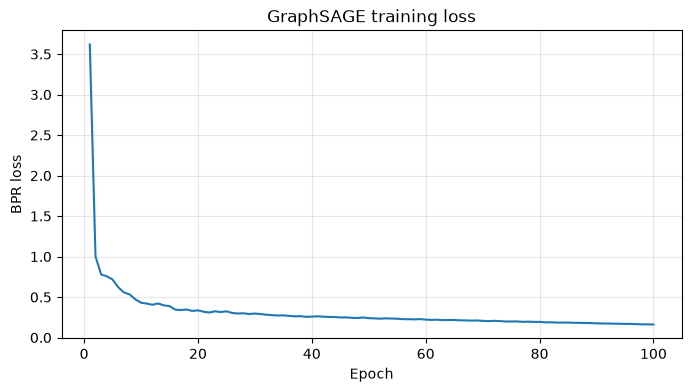

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    range(
        1,
        len(graph_training_result.losses) + 1,
    ),
    graph_training_result.losses,
)

plt.xlabel("Epoch")
plt.ylabel("BPR loss")
plt.title("GraphSAGE training loss")
plt.grid(alpha=0.3)
plt.show()

In [19]:
graph_embeddings = extract_graph_embeddings(
    training_result=graph_training_result,
    graph=train_graph,
)

In [21]:
scored_validation_candidates = (
    graph_embeddings.score_candidates(
        validation_candidates,
        score_col="graph_score",
    )
)

In [22]:
scored_validation_candidates = (
    scored_validation_candidates
    .sort_values(
        ["user_id", "graph_score"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

scored_validation_candidates["graph_rank"] = (
    scored_validation_candidates
    .groupby("user_id")
    .cumcount()
    + 1
)

display(
    scored_validation_candidates.head(10)
)

,user_id,item_id,als_score,als_rank,graph_score,graph_rank
0,840,10440,0.271781,48,22.680273,1
1,840,4151,0.242502,68,22.650150,2
2,840,9728,1.180441,1,22.566902,3
3,840,2657,0.526042,6,22.414551,4
4,840,9996,0.411979,16,22.286613,5
5,840,4880,0.333670,33,22.244436,6
6,840,7107,0.163896,152,22.133047,7
7,840,7417,0.428973,10,22.087893,8
8,840,1844,0.143877,197,22.045517,9
9,840,14431,0.388069,23,21.922874,10


In [26]:
graph_validation_ndcg_10 = (
    ndcg_at_k_from_scores(
        scored_candidates=(
            scored_validation_candidates
        ),
        targets=validation_targets,
        score_col="graph_score",
        k=10,
    )
)

print(
    "GraphSAGE validation NDCG@10: "
    f"{graph_validation_ndcg_10:.5f}"
)

GraphSAGE validation NDCG@10: 0.09698


In [30]:
als_validation_ndcg = evaluate_ndcg_at_k(
    model=validation_als,
    targets=validation_targets,
    k=10,
    batch_size=BATCH_SIZE,
)

NDCG@10:   0%|          | 0/2 [00:00<?, ?it/s]

In [31]:
validation_comparison = pd.DataFrame(
    {
        "Модель": [
            "ALS",
            "GraphSAGE dot product",
        ],
        "Validation NDCG@10": [
            als_validation_ndcg["ndcg@10_all"],
            graph_validation_ndcg_10,
        ],
    }
)

validation_comparison["Прирост к ALS"] = (
    validation_comparison[
        "Validation NDCG@10"
    ]
    / als_validation_ndcg["ndcg@10_all"]
    - 1
)

display(
    validation_comparison.style.format(
        {
            "Validation NDCG@10": "{:.5f}",
            "Прирост к ALS": "{:+.2%}",
        }
    )
)

,Модель,Validation NDCG@10,Прирост к ALS
0,ALS,0.04831,+0.00%
1,GraphSAGE dot product,0.09698,+100.75%


In [33]:
import gc
import time

graph_trials = [
    {
        "params": graph_params.copy(),
        "validation_ndcg@10": (
            graph_validation_ndcg_10
        ),
        "final_train_loss": (
            graph_training_result.losses[-1]
        ),
    }
]

In [34]:
EXTRA_GRAPH_PARAM_GRID = [
    {
        **graph_params,
        "hidden_dim": 32,
    },
    {
        **graph_params,
        "hidden_dim": 128,
    },
    {
        **graph_params,
        "negatives_per_positive": 10,
    },
    {
        **graph_params,
        "learning_rate": 3e-3,
    },
]

In [35]:
for trial_number, params in enumerate(
    EXTRA_GRAPH_PARAM_GRID,
    start=2,
):
    print()
    print(
        f"GraphSAGE trial "
        f"{trial_number}/"
        f"{len(EXTRA_GRAPH_PARAM_GRID) + 1}"
    )
    print(params)

    started_at = time.perf_counter()

    trial_training_result = train_graph_model(
        graph=train_graph,
        **params,
        random_state=RANDOM_STATE,
        verbose=20,
    )

    trial_embeddings = extract_graph_embeddings(
        training_result=trial_training_result,
        graph=train_graph,
    )

    trial_scored_candidates = (
        trial_embeddings.score_candidates(
            validation_candidates,
            score_col="graph_score",
        )
    )

    trial_ndcg = ndcg_at_k_from_scores(
        scored_candidates=trial_scored_candidates,
        targets=validation_targets,
        score_col="graph_score",
        k=10,
    )

    elapsed_seconds = (
        time.perf_counter() - started_at
    )

    graph_trials.append(
        {
            "params": params.copy(),
            "validation_ndcg@10": trial_ndcg,
            "final_train_loss": (
                trial_training_result.losses[-1]
            ),
            "fit_and_evaluation_seconds": (
                elapsed_seconds
            ),
        }
    )

    print(
        "Validation NDCG@10: "
        f"{trial_ndcg:.5f}"
    )

    print(
        "Последний train loss: "
        f"{trial_training_result.losses[-1]:.6f}"
    )

    print(
        "Время: "
        f"{elapsed_seconds:.1f} секунд"
    )

    del trial_training_result
    del trial_embeddings
    del trial_scored_candidates

    gc.collect()


GraphSAGE trial 2/5
{'hidden_dim': 32, 'num_layers': 2, 'dropout': 0.1, 'epochs': 100, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'negatives_per_positive': 5, 'embedding_regularization': 1e-06}
Epoch 001/100: BPR loss = 1.530216
Epoch 020/100: BPR loss = 0.355215
Epoch 040/100: BPR loss = 0.290631
Epoch 060/100: BPR loss = 0.247276
Epoch 080/100: BPR loss = 0.203671
Epoch 100/100: BPR loss = 0.162818
Validation NDCG@10: 0.08902
Последний train loss: 0.162818
Время: 9.9 секунд

GraphSAGE trial 3/5
{'hidden_dim': 128, 'num_layers': 2, 'dropout': 0.1, 'epochs': 100, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'negatives_per_positive': 5, 'embedding_regularization': 1e-06}
Epoch 001/100: BPR loss = 2.703150
Epoch 020/100: BPR loss = 0.305845
Epoch 040/100: BPR loss = 0.236801
Epoch 060/100: BPR loss = 0.196821
Epoch 080/100: BPR loss = 0.165482
Epoch 100/100: BPR loss = 0.136432
Validation NDCG@10: 0.09205
Последний train loss: 0.136432
Время: 31.6 секунд

GraphSAGE trial 4/5
{'hid

In [36]:
graph_validation_results = pd.DataFrame(
    [
        {
            **trial["params"],
            "Validation NDCG@10": (
                trial["validation_ndcg@10"]
            ),
            "Final train loss": (
                trial["final_train_loss"]
            ),
            "Seconds": trial.get(
                "fit_and_evaluation_seconds",
                np.nan,
            ),
        }
        for trial in graph_trials
    ]
)

graph_validation_results = (
    graph_validation_results
    .sort_values(
        "Validation NDCG@10",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    graph_validation_results.style.format(
        {
            "learning_rate": "{:.4f}",
            "weight_decay": "{:.1e}",
            "embedding_regularization": "{:.1e}",
            "Validation NDCG@10": "{:.5f}",
            "Final train loss": "{:.6f}",
            "Seconds": "{:.1f}",
        }
    )
)

,hidden_dim,num_layers,dropout,epochs,learning_rate,weight_decay,negatives_per_positive,embedding_regularization,Validation NDCG@10,Final train loss,Seconds
0,64,2,0.100000,100,0.0010,1.0e-05,10,1.0e-06,0.09734,0.160365,25.7
1,64,2,0.100000,100,0.0010,1.0e-05,5,1.0e-06,0.09698,0.161473,nan
2,128,2,0.100000,100,0.0010,1.0e-05,5,1.0e-06,0.09205,0.136432,31.6
3,32,2,0.100000,100,0.0010,1.0e-05,5,1.0e-06,0.08902,0.162818,9.9
4,64,2,0.100000,100,0.0030,1.0e-05,5,1.0e-06,0.08258,0.106100,15.7


In [37]:
best_graph_trial = max(
    graph_trials,
    key=lambda trial: trial[
        "validation_ndcg@10"
    ],
)

best_graph_params = (
    best_graph_trial["params"].copy()
)

best_graph_validation_ndcg = (
    best_graph_trial[
        "validation_ndcg@10"
    ]
)

print("Лучшие параметры:")
print(best_graph_params)

print(
    "Лучший Validation NDCG@10: "
    f"{best_graph_validation_ndcg:.5f}"
)

Лучшие параметры:
{'hidden_dim': 64, 'num_layers': 2, 'dropout': 0.1, 'epochs': 100, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'negatives_per_positive': 10, 'embedding_regularization': 1e-06}
Лучший Validation NDCG@10: 0.09734


обучение на train + validation и проверка на test

In [38]:
final_graph_history = (
    pd.concat(
        [
            train,
            validation,
        ],
        ignore_index=True,
    )
    .reset_index(drop=True)
)

print(
    "Финальная история:",
    len(final_graph_history),
)

print(
    "Пользователей:",
    final_graph_history["user_id"].nunique(),
)

print(
    "Фильмов:",
    final_graph_history["item_id"].nunique(),
)

Финальная история: 30166
Пользователей: 10000
Фильмов: 4186


In [39]:
final_graph = build_heterogeneous_graph(
    interactions=final_graph_history,
    users=users,
    items=items,
    cutoff=VALIDATION_CUTOFF,
)

for node_type in final_graph.data.node_types:
    print(
        f"{node_type}: "
        f"{final_graph.data[node_type].num_nodes:,} nodes"
    )

print()

for edge_type in final_graph.data.edge_types:
    edge_count = (
        final_graph.data[edge_type]
        .edge_index
        .shape[1]
    )

    print(
        f"{edge_type}: "
        f"{edge_count:,} edges"
    )

user: 10,000 nodes
item: 4,186 nodes
genre: 72 nodes
country: 78 nodes
content_type: 2 nodes

('user', 'watched', 'item'): 30,166 edges
('item', 'watched_by', 'user'): 30,166 edges
('item', 'has_genre', 'genre'): 10,622 edges
('genre', 'genre_of', 'item'): 10,622 edges
('item', 'made_in', 'country'): 5,471 edges
('country', 'country_of', 'item'): 5,471 edges
('item', 'has_type', 'content_type'): 4,186 edges
('content_type', 'type_of', 'item'): 4,186 edges


In [40]:
final_graph_started = time.perf_counter()

final_graph_training_result = train_graph_model(
    graph=final_graph,
    **best_graph_params,
    random_state=RANDOM_STATE,
    verbose=10,
)

final_graph_fit_seconds = (
    time.perf_counter()
    - final_graph_started
)

print(
    "Обучение заняло: "
    f"{final_graph_fit_seconds:.1f} секунд"
)

Epoch 001/100: BPR loss = 1.031044
Epoch 010/100: BPR loss = 0.327402
Epoch 020/100: BPR loss = 0.276697
Epoch 030/100: BPR loss = 0.247366
Epoch 040/100: BPR loss = 0.218932
Epoch 050/100: BPR loss = 0.202725
Epoch 060/100: BPR loss = 0.173689
Epoch 070/100: BPR loss = 0.151633
Epoch 080/100: BPR loss = 0.130337
Epoch 090/100: BPR loss = 0.114051
Epoch 100/100: BPR loss = 0.100136
Обучение заняло: 33.3 секунд


In [41]:
final_graph_embeddings = extract_graph_embeddings(
    training_result=final_graph_training_result,
    graph=final_graph,
)

print(
    "User embeddings:",
    final_graph_embeddings.user_embeddings.shape,
)

print(
    "Item embeddings:",
    final_graph_embeddings.item_embeddings.shape,
)

User embeddings: (10000, 64)
Item embeddings: (4186, 64)


In [43]:
final_als_history = (
    final_graph_history[
        ["user_id", "item_id"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

In [44]:
final_als = ALSCandidateModel(
    **best_params,
    random_state=RANDOM_STATE,
    num_threads=0,
)

final_als.fit(
    interactions=final_als_history,
    show_progress=True,
)

  0%|          | 0/20 [00:00<?, ?it/s]

In [46]:
test_user_ids = (
    test_targets["user_id"]
    .drop_duplicates()
    .tolist()
)

test_candidates = final_als.recommend(
    user_ids=test_user_ids,
    n=K,
    filter_seen=True,
    batch_size=BATCH_SIZE,
)

test_candidates = (
    test_candidates
    .sort_values(["user_id", "als_rank"])
    .reset_index(drop=True)
)


In [47]:
scored_test_candidates = (
    final_graph_embeddings.score_candidates(
        test_candidates,
        score_col="graph_score",
    )
)

In [48]:
scored_test_candidates = (
    scored_test_candidates
    .sort_values(
        ["user_id", "graph_score"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

scored_test_candidates["graph_rank"] = (
    scored_test_candidates
    .groupby("user_id")
    .cumcount()
    + 1
)

display(
    scored_test_candidates.head(10)
)

,user_id,item_id,als_score,als_rank,graph_score,graph_rank
0,1000,849,0.238002,21,20.688824,1
1,1000,6809,0.113116,131,20.518387,2
2,1000,2237,0.173626,52,20.282597,3
3,1000,15297,0.099398,155,20.163746,4
4,1000,8636,0.256510,15,20.107019,5
5,1000,16361,0.234834,24,20.076578,6
6,1000,101,0.453174,1,19.981930,7
7,1000,657,0.150729,65,19.971157,8
8,1000,12463,0.357440,6,19.957859,9
9,1000,1916,0.248003,18,19.920292,10


In [49]:
graph_test_ndcg_10 = ndcg_at_k_from_scores(
    scored_candidates=scored_test_candidates,
    targets=test_targets,
    score_col="graph_score",
    k=10,
)

print(
    "GraphSAGE Test NDCG@10: "
    f"{graph_test_ndcg_10:.5f}"
)

GraphSAGE Test NDCG@10: 0.04767


Проверим, что ALS и oracle выдают те же результаты, что и в первом блокноте

In [50]:
als_test_ndcg = evaluate_ndcg_at_k(
    model=final_als,
    targets=test_targets,
    k=10,
    batch_size=BATCH_SIZE,
)

NDCG@10:   0%|          | 0/1 [00:00<?, ?it/s]

In [51]:
test_oracle_ndcg_10 = oracle_ndcg_at_k(
    candidates=test_candidates,
    targets=test_targets,
    k=10,
)

In [52]:
graph_test_comparison = pd.DataFrame(
    {
        "Модель": [
            "ALS",
            "GraphSAGE dot product",
            "Oracle среди 200 кандидатов",
        ],
        "Test NDCG@10": [
            als_test_ndcg["ndcg@10_all"],
            graph_test_ndcg_10,
            test_oracle_ndcg_10,
        ],
    }
)

graph_test_comparison[
    "Прирост относительно ALS"
] = (
    graph_test_comparison["Test NDCG@10"]
    / als_test_ndcg["ndcg@10_all"]
    - 1
)

display(
    graph_test_comparison.style.format(
        {
            "Test NDCG@10": "{:.5f}",
            "Прирост относительно ALS": "{:+.2%}",
        }
    )
)

,Модель,Test NDCG@10,Прирост относительно ALS
0,ALS,0.03081,+0.00%
1,GraphSAGE dot product,0.04767,+54.74%
2,Oracle среди 200 кандидатов,0.27946,+807.19%


### Бустинг на признаках графа

In [115]:
import importlib

import src.graph_features
import src

from src import build_graph_pair_features

In [116]:
RANKER_TRAIN_CUTOFF = "2021-06-01"

train_dates = pd.to_datetime(
    train["last_watch_dt"]
)

ranker_history = (
    train[
        train_dates
        < pd.Timestamp(RANKER_TRAIN_CUTOFF)
    ]
    .copy()
    .reset_index(drop=True)
)

ranker_train_targets = (
    train[
        train_dates
        >= pd.Timestamp(RANKER_TRAIN_CUTOFF)
    ][["user_id", "item_id"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    "История до июня:",
    len(ranker_history),
)

print(
    "Июньских positives:",
    len(ranker_train_targets),
)

История до июня: 13982
Июньских positives: 10718


In [117]:
ranker_train_graph = (
    build_heterogeneous_graph(
        interactions=ranker_history,
        users=users,
        items=items,
        cutoff=RANKER_TRAIN_CUTOFF,
    )
)

In [58]:
ranker_graph_training_result = (
    train_graph_model(
        graph=ranker_train_graph,
        **best_graph_params,
        random_state=RANDOM_STATE,
        verbose=10,
    )
)

ranker_graph_embeddings = (
    extract_graph_embeddings(
        training_result=(
            ranker_graph_training_result
        ),
        graph=ranker_train_graph,
    )
)

Epoch 001/100: BPR loss = 1.401176
Epoch 010/100: BPR loss = 0.418522
Epoch 020/100: BPR loss = 0.292717
Epoch 030/100: BPR loss = 0.240007
Epoch 040/100: BPR loss = 0.201937
Epoch 050/100: BPR loss = 0.166385
Epoch 060/100: BPR loss = 0.132241
Epoch 070/100: BPR loss = 0.113453
Epoch 080/100: BPR loss = 0.093895
Epoch 090/100: BPR loss = 0.077753
Epoch 100/100: BPR loss = 0.068561


In [59]:
ranker_train_als = ALSCandidateModel(
    **best_params,
    random_state=RANDOM_STATE,
    num_threads=0,
)

ranker_train_als.fit(
    interactions=ranker_history[
        ["user_id", "item_id"]
    ],
    show_progress=True,
)

  0%|          | 0/20 [00:00<?, ?it/s]

In [60]:
ranker_train_user_ids = (
    ranker_train_targets["user_id"]
    .drop_duplicates()
    .tolist()
)

ranker_train_candidates = (
    ranker_train_als.recommend(
        user_ids=ranker_train_user_ids,
        n=K,
        filter_seen=True,
        batch_size=BATCH_SIZE,
    )
)

In [61]:
def add_candidate_labels(
    candidates: pd.DataFrame,
    targets: pd.DataFrame,
) -> pd.DataFrame:
    positive_pairs = (
        targets[
            ["user_id", "item_id"]
        ]
        .drop_duplicates()
        .assign(label=1)
    )

    result = candidates.merge(
        positive_pairs,
        on=["user_id", "item_id"],
        how="left",
        validate="one_to_one",
    )

    result["label"] = (
        result["label"]
        .fillna(0)
        .astype("int8")
    )

    return result

In [62]:
ranker_train_candidates = (
    add_candidate_labels(
        candidates=ranker_train_candidates,
        targets=ranker_train_targets,
    )
)

In [63]:
positive_train_users = (
    ranker_train_candidates
    .groupby("user_id")["label"]
    .max()
)

positive_train_users = (
    positive_train_users[
        positive_train_users == 1
    ]
    .index
)

ranker_train_candidates = (
    ranker_train_candidates[
        ranker_train_candidates[
            "user_id"
        ].isin(positive_train_users)
    ]
    .sort_values(
        ["user_id", "als_rank"]
    )
    .reset_index(drop=True)
)

print(
    "Обучающих пользователей:",
    len(positive_train_users),
)

print(
    "Положительных кандидатов:",
    ranker_train_candidates[
        "label"
    ].sum(),
)

Обучающих пользователей: 552
Положительных кандидатов: 701


In [ ]:
X_graph_train, graph_categorical_columns = (
    build_graph_pair_features(
        candidates=(
            ranker_train_candidates.drop(
                columns="label"
            )
        ),
        embeddings=ranker_graph_embeddings,
    )
)

y_graph_train = (
    ranker_train_candidates["label"]
    .to_numpy()
)

graph_train_group_ids = (
    ranker_train_candidates["user_id"]
    .to_numpy()
)

print(X_graph_train.shape)
print(X_graph_train.columns.tolist())

(110400, 9)
['user_id', 'item_id', 'als_score', 'als_rank', 'graph_dot_product', 'graph_cosine_similarity', 'graph_l2_distance', 'graph_user_norm', 'graph_item_norm']


In [65]:
validation_graph_training_result = (
    train_graph_model(
        graph=train_graph,
        **best_graph_params,
        random_state=RANDOM_STATE,
        verbose=10,
    )
)

validation_graph_embeddings = (
    extract_graph_embeddings(
        training_result=(
            validation_graph_training_result
        ),
        graph=train_graph,
    )
)

Epoch 001/100: BPR loss = 3.602919
Epoch 010/100: BPR loss = 0.433398
Epoch 020/100: BPR loss = 0.337512
Epoch 030/100: BPR loss = 0.296843
Epoch 040/100: BPR loss = 0.259219
Epoch 050/100: BPR loss = 0.238893
Epoch 060/100: BPR loss = 0.221710
Epoch 070/100: BPR loss = 0.204134
Epoch 080/100: BPR loss = 0.194801
Epoch 090/100: BPR loss = 0.173359
Epoch 100/100: BPR loss = 0.160365


In [66]:
labeled_validation_candidates = (
    add_candidate_labels(
        candidates=validation_candidates,
        targets=validation_targets,
    )
    .sort_values(
        ["user_id", "als_rank"]
    )
    .reset_index(drop=True)
)

In [67]:
X_graph_validation, _ = (
    build_graph_pair_features(
        candidates=(
            labeled_validation_candidates.drop(
                columns="label"
            )
        ),
        embeddings=validation_graph_embeddings,
    )
)

X_graph_validation = (
    X_graph_validation[
        X_graph_train.columns
    ]
)

y_graph_validation = (
    labeled_validation_candidates["label"]
    .to_numpy()
)

graph_validation_group_ids = (
    labeled_validation_candidates["user_id"]
    .to_numpy()
)

In [68]:
graph_train_pool = Pool(
    data=X_graph_train,
    label=y_graph_train,
    group_id=graph_train_group_ids,
    cat_features=graph_categorical_columns,
)

graph_validation_pool = Pool(
    data=X_graph_validation,
    label=y_graph_validation,
    group_id=graph_validation_group_ids,
    cat_features=graph_categorical_columns,
)

In [69]:
graph_catboost_ranker = CatBoostRanker(
    loss_function="YetiRank",
    eval_metric="NDCG:top=10",
    iterations=1_000,
    learning_rate=0.05,
    depth=8,
    l2_leaf_reg=5.0,
    random_seed=RANDOM_STATE,
    verbose=100,
    allow_writing_files=False,
)

graph_catboost_ranker.fit(
    graph_train_pool,
    eval_set=graph_validation_pool,
    early_stopping_rounds=100,
    use_best_model=True,
)

Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.6294703	best: 0.6294703 (0)	total: 202ms	remaining: 3m 22s
100:	test: 0.6603821	best: 0.6710472 (47)	total: 16.3s	remaining: 2m 24s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.6710472415
bestIteration = 47

Shrink model to first 48 iterations.


CatBoostRanker(allow_writing_files=False, depth=8, eval_metric='NDCG:top=10', iterations=1000, l2_leaf_reg=5.0, learning_rate=0.05, loss_function='YetiRank', random_seed=42, verbose=100)

In [71]:
graph_catboost_validation_scores = (
    graph_catboost_ranker.predict(
        X_graph_validation
    )
)

graph_catboost_validation_candidates = (
    labeled_validation_candidates[
        ["user_id", "item_id"]
    ]
    .copy()
)

graph_catboost_validation_candidates[
    "score"
] = graph_catboost_validation_scores

In [72]:
graph_catboost_validation_ndcg = (
    ndcg_at_k_from_scores(
        scored_candidates=(
            graph_catboost_validation_candidates
        ),
        targets=validation_targets,
        score_col="score",
        k=10,
    )
)

print(
    "GraphSAGE + CatBoost "
    "Validation NDCG@10: "
    f"{graph_catboost_validation_ndcg:.5f}"
)

GraphSAGE + CatBoost Validation NDCG@10: 0.08488


In [74]:
feature_importance_values = (
    graph_catboost_ranker
    .get_feature_importance(
        data=graph_train_pool,
        type="LossFunctionChange",
    )
)

graph_feature_importance = (
    pd.DataFrame(
        {
            "feature": X_graph_train.columns,
            "importance": (
                feature_importance_values
            ),
        }
    )
    .sort_values(
        "importance",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(graph_feature_importance)

,feature,importance
0,graph_item_norm,0.019771
1,als_rank,0.006512
2,als_score,0.003192
3,graph_l2_distance,0.000515
4,graph_dot_product,0.000240
5,graph_cosine_similarity,0.000228
6,graph_user_norm,0.000189
7,user_id,0.000000
8,item_id,0.000000


проверим на тесте

In [96]:
positive_validation_users = (
    labeled_validation_candidates
    .groupby("user_id")["label"]
    .max()
)

positive_validation_users = (
    positive_validation_users[
        positive_validation_users == 1
    ]
    .index
)

validation_train_mask = (
    labeled_validation_candidates[
        "user_id"
    ].isin(positive_validation_users)
)

print(
    "Validation-групп для обучения:",
    len(positive_validation_users),
)

Validation-групп для обучения: 990


In [97]:
X_graph_validation_for_train = (
    X_graph_validation.loc[
        validation_train_mask
    ]
    .reset_index(drop=True)
)

y_graph_validation_for_train = (
    labeled_validation_candidates.loc[
        validation_train_mask,
        "label",
    ]
    .to_numpy()
)

validation_users_for_train = (
    labeled_validation_candidates.loc[
        validation_train_mask,
        "user_id",
    ]
    .reset_index(drop=True)
)

In [98]:
X_final_graph_catboost_train = (
    pd.concat(
        [
            X_graph_train.reset_index(
                drop=True
            ),
            X_graph_validation_for_train,
        ],
        ignore_index=True,
    )
)

y_final_graph_catboost_train = (
    np.concatenate(
        [
            y_graph_train,
            y_graph_validation_for_train,
        ]
    )
)

In [99]:
june_group_keys = (
    "june_"
    + ranker_train_candidates[
        "user_id"
    ]
    .astype(str)
    .reset_index(drop=True)
)

july_group_keys = (
    "july_"
    + validation_users_for_train
    .astype(str)
)

final_graph_group_keys = (
    pd.concat(
        [
            june_group_keys,
            july_group_keys,
        ],
        ignore_index=True,
    )
)

final_graph_catboost_group_ids = (
    pd.factorize(
        final_graph_group_keys,
        sort=False,
    )[0]
)

In [100]:
print(
    "Финальный train:",
    X_final_graph_catboost_train.shape,
)

print(
    "Групп:",
    len(
        np.unique(
            final_graph_catboost_group_ids
        )
    ),
)

print(
    "Positives:",
    int(
        y_final_graph_catboost_train.sum()
    ),
)

Финальный train: (308400, 9)
Групп: 1542
Positives: 2049


In [101]:
best_graph_catboost_iterations = (
    graph_catboost_ranker
    .get_best_iteration()
    + 1
)

if best_graph_catboost_iterations <= 0:
    best_graph_catboost_iterations = 1_000

print(
    "Итераций:",
    best_graph_catboost_iterations,
)

Итераций: 48


In [103]:
final_graph_catboost_pool = Pool(
    data=X_final_graph_catboost_train,
    label=y_final_graph_catboost_train,
    group_id=(
        final_graph_catboost_group_ids
    ),
    cat_features=(
        graph_categorical_columns
    ),
)

In [104]:
final_graph_catboost_ranker = (
    CatBoostRanker(
        loss_function="YetiRank",
        eval_metric="NDCG:top=10",
        iterations=(
            best_graph_catboost_iterations
        ),
        learning_rate=0.05,
        depth=8,
        l2_leaf_reg=5.0,
        random_seed=RANDOM_STATE,
        verbose=100,
        allow_writing_files=False,
    )
)

final_graph_catboost_ranker.fit(
    final_graph_catboost_pool
)

Groupwise loss function. OneHotMaxSize set to 10
0:	total: 404ms	remaining: 19s
47:	total: 12.9s	remaining: 0us


CatBoostRanker(allow_writing_files=False, depth=8, eval_metric='NDCG:top=10', iterations=48, l2_leaf_reg=5.0, learning_rate=0.05, loss_function='YetiRank', random_seed=42, verbose=100)

In [105]:
X_graph_test, _ = (
    build_graph_pair_features(
        candidates=test_candidates,
        embeddings=final_graph_embeddings,
    )
)

X_graph_test = X_graph_test[
    X_final_graph_catboost_train.columns
]

print(
    "Test features:",
    X_graph_test.shape,
)

Test features: (278200, 9)


In [106]:
graph_catboost_test_scores = (
    final_graph_catboost_ranker.predict(
        X_graph_test
    )
)

scored_graph_catboost_test = (
    test_candidates[
        ["user_id", "item_id"]
    ]
    .copy()
)

scored_graph_catboost_test["score"] = (
    graph_catboost_test_scores
)

In [107]:
graph_catboost_test_ndcg = (
    ndcg_at_k_from_scores(
        scored_candidates=(
            scored_graph_catboost_test
        ),
        targets=test_targets,
        score_col="score",
        k=10,
    )
)

print(
    "Graph CatBoost Test NDCG@10: "
    f"{graph_catboost_test_ndcg:.5f}"
)

Graph CatBoost Test NDCG@10: 0.03129


## Улучшенный GraphSAGE: edge dropout и 60 эпох

По результатам отдельных temporal-экспериментов используем 20% edge dropout только во время message passing. Рёбра остаются positives в BPR loss, а финальные embeddings считаются на полном графе.

In [108]:
import time

import torch
from torch.nn import functional as F

from models.graph_model import (
    GraphTrainingResult,
    HeterogeneousGraphSAGE,
    sample_bpr_negatives,
)

In [109]:
def train_graph_model_with_edge_dropout(
    graph,
    *,
    hidden_dim=64,
    num_layers=2,
    dropout=0.1,
    edge_dropout=0.2,
    epochs=60,
    learning_rate=1e-3,
    weight_decay=1e-5,
    negatives_per_positive=10,
    embedding_regularization=1e-6,
    random_state=42,
    verbose=10,
):
    if not 0 <= edge_dropout < 1:
        raise ValueError(
            "edge_dropout must be in [0, 1)"
        )

    device = torch.device("cpu")
    torch.manual_seed(random_state)

    data = graph.data.clone().to(device)

    model = HeterogeneousGraphSAGE(
        data=data,
        hidden_dim=hidden_dim,
        num_layers=num_layers,
        dropout=dropout,
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay,
    )

    positive_edges = data[
        "user", "watched", "item"
    ].edge_index

    generator = torch.Generator(
        device=device
    )
    generator.manual_seed(random_state)

    losses = []

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)

        keep_edges = (
            torch.rand(
                positive_edges.shape[1],
                generator=generator,
                device=device,
            )
            >= edge_dropout
        )

        message_edges = (
            positive_edges[:, keep_edges]
        )

        message_data = data.clone()
        message_data[
            "user", "watched", "item"
        ].edge_index = message_edges
        message_data[
            "item", "watched_by", "user"
        ].edge_index = message_edges.flip(0)

        embeddings = model(message_data)

        (
            sampled_users,
            positive_items,
            negative_items,
        ) = sample_bpr_negatives(
            positive_edges=positive_edges,
            num_items=data["item"].num_nodes,
            negatives_per_positive=(
                negatives_per_positive
            ),
            generator=generator,
        )

        positive_scores = model.score_pairs(
            embeddings["user"],
            embeddings["item"],
            sampled_users,
            positive_items,
        )

        negative_scores = model.score_pairs(
            embeddings["user"],
            embeddings["item"],
            sampled_users,
            negative_items,
        )

        ranking_loss = -F.logsigmoid(
            positive_scores - negative_scores
        ).mean()

        regularization = (
            embedding_regularization
            * (
                embeddings["user"]
                [sampled_users]
                .pow(2)
                .mean()
                + embeddings["item"]
                [positive_items]
                .pow(2)
                .mean()
                + embeddings["item"]
                [negative_items]
                .pow(2)
                .mean()
            )
        )

        loss = ranking_loss + regularization
        loss.backward()
        optimizer.step()

        loss_value = float(
            loss.detach().cpu()
        )
        losses.append(loss_value)

        if (
            epoch == 1
            or epoch % verbose == 0
            or epoch == epochs
        ):
            print(
                f"Epoch {epoch:03d}/{epochs}: "
                f"BPR loss = {loss_value:.6f}"
            )

    return GraphTrainingResult(
        model=model,
        losses=losses,
        device=str(device),
    )

In [110]:
IMPROVED_GRAPH_PARAMS = {
    "hidden_dim": 64,
    "num_layers": 2,
    "dropout": 0.1,
    "edge_dropout": 0.2,
    "epochs": 60,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "negatives_per_positive": 10,
    "embedding_regularization": 1e-6,
}

improved_fit_started = time.perf_counter()

improved_graph_training_result = (
    train_graph_model_with_edge_dropout(
        graph=final_graph,
        **IMPROVED_GRAPH_PARAMS,
        random_state=RANDOM_STATE,
        verbose=10,
    )
)

improved_fit_seconds = (
    time.perf_counter()
    - improved_fit_started
)

print(
    "Обучение заняло: "
    f"{improved_fit_seconds:.1f} секунд"
)

Epoch 001/60: BPR loss = 1.080602
Epoch 010/60: BPR loss = 0.358584
Epoch 020/60: BPR loss = 0.300607
Epoch 030/60: BPR loss = 0.270277
Epoch 040/60: BPR loss = 0.250014
Epoch 050/60: BPR loss = 0.230166
Epoch 060/60: BPR loss = 0.215821
Обучение заняло: 31.7 секунд


In [113]:
improved_graph_embeddings = (
    extract_graph_embeddings(
        training_result=(
            improved_graph_training_result
        ),
        graph=final_graph,
    )
)

improved_scored_test_candidates = (
    improved_graph_embeddings
    .score_candidates(
        test_candidates,
        score_col="graph_score",
    )
)

improved_graph_test_ndcg_10 = (
    ndcg_at_k_from_scores(
        scored_candidates=(
            improved_scored_test_candidates
        ),
        targets=test_targets,
        score_col="graph_score",
        k=10,
    )
)

print(
    "Improved GraphSAGE Test NDCG@10: "
    f"{improved_graph_test_ndcg_10:.5f}"
)

Improved GraphSAGE Test NDCG@10: 0.05071
